✅ Dataset cargado e introducido con éxito. Registros limpios: 297
📊 Conjunto de Entrenamiento: 237 muestras | Prueba: 60 muestras

--- TABLA COMPARATIVA DE RENDIMIENTO EN TEST ---
             Modelo  Accuracy  Precision  Recall (Sensibilidad)  F1-Score  ROC-AUC
      Random Forest  0.850000   0.851852               0.821429  0.836364 0.911830
          SVM (RBF)  0.833333   0.846154               0.785714  0.814815 0.935268
                KNN  0.833333   0.875000               0.750000  0.807692 0.894531
Regresión Logística  0.800000   0.833333               0.714286  0.769231 0.928571
  Árbol de Decisión  0.783333   0.800000               0.714286  0.754717 0.779018
  Gradient Boosting  0.800000   0.833333               0.714286  0.769231 0.887277

✨ Mejores Parámetros (Optimizado para Recall): {'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 50}


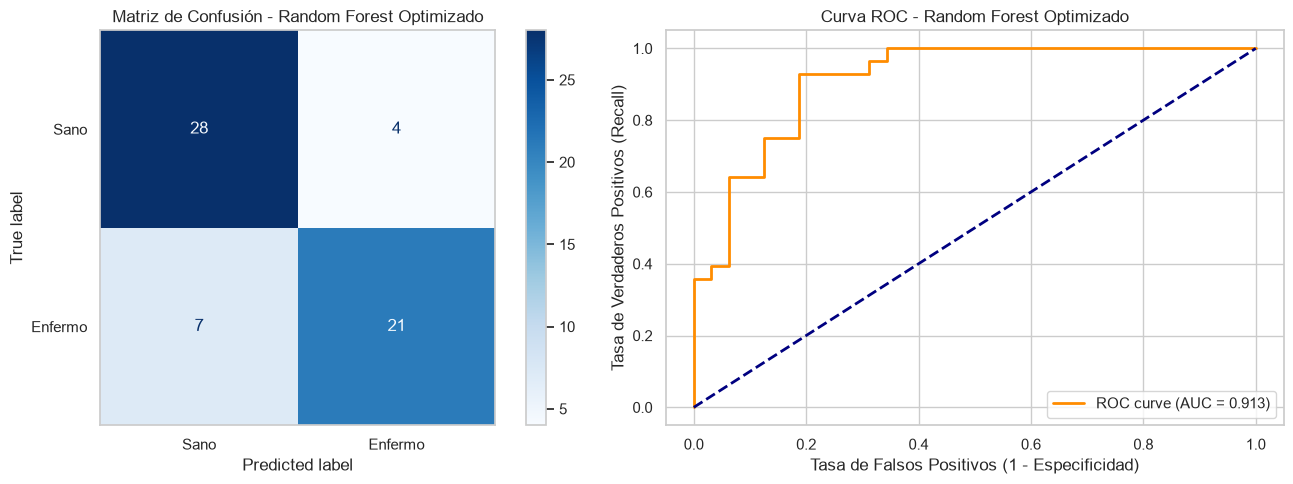

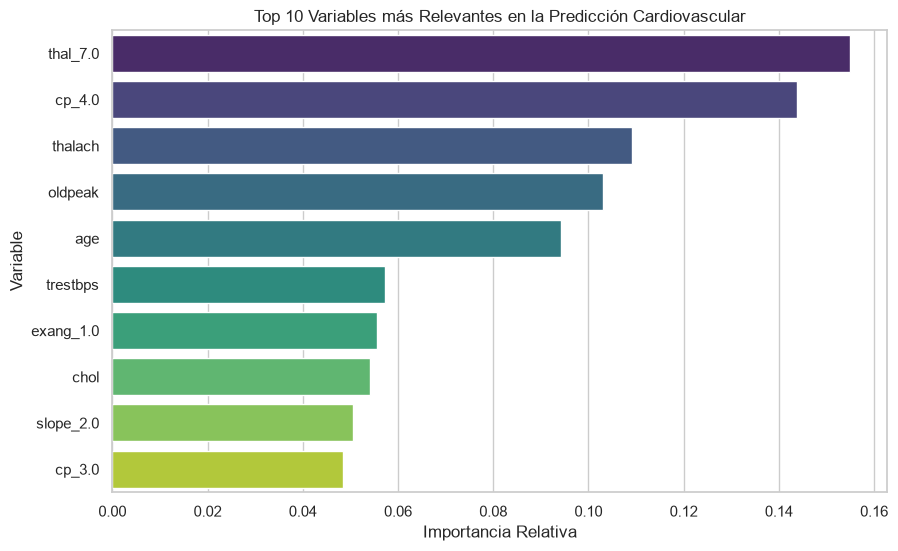

✅ Dataset cargado e introducido con éxito. Registros limpios: 297
📊 Conjunto de Entrenamiento: 237 muestras | Prueba: 60 muestras

--- TABLA COMPARATIVA DE RENDIMIENTO EN TEST ---
             Modelo  Accuracy  Precision  Recall (Sensibilidad)  F1-Score  ROC-AUC
      Random Forest  0.850000   0.851852               0.821429  0.836364 0.911830
          SVM (RBF)  0.833333   0.846154               0.785714  0.814815 0.935268
                KNN  0.833333   0.875000               0.750000  0.807692 0.894531
Regresión Logística  0.800000   0.833333               0.714286  0.769231 0.928571
  Árbol de Decisión  0.783333   0.800000               0.714286  0.754717 0.779018
  Gradient Boosting  0.800000   0.833333               0.714286  0.769231 0.887277

✨ Mejores Parámetros (Optimizado para Recall): {'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 50}


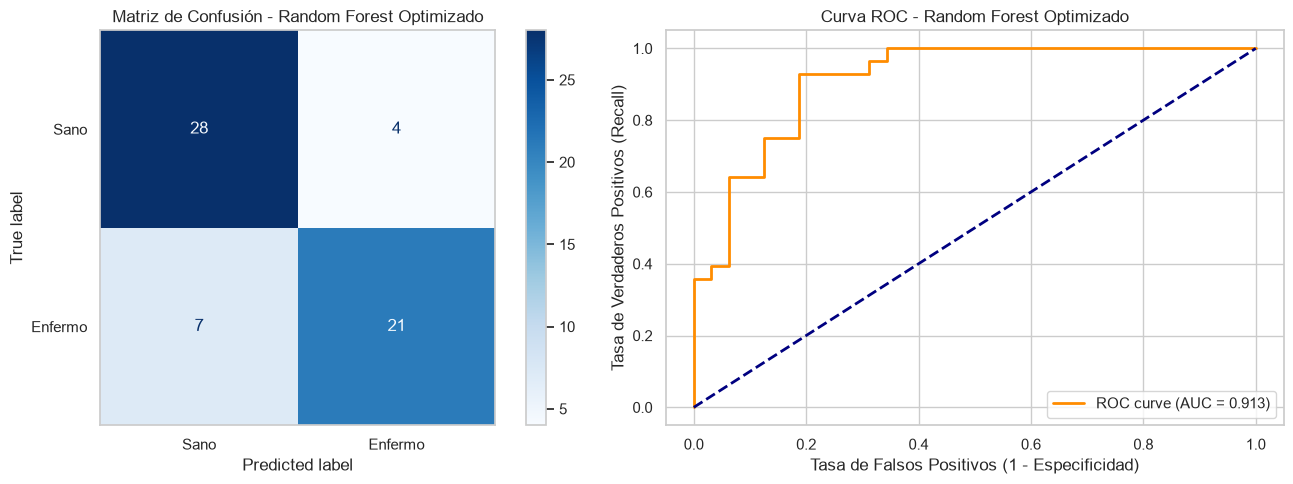

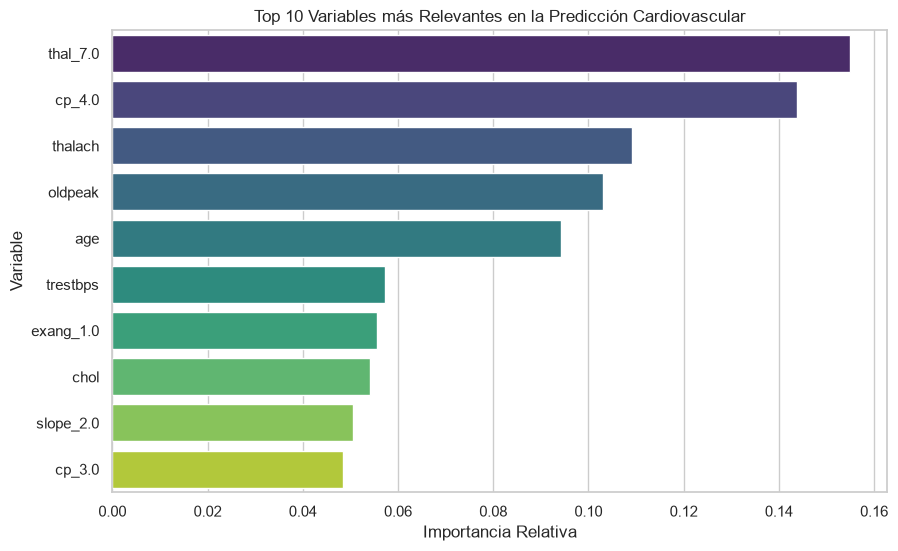

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Selección de Modelos y Evaluación
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve
)

# Algoritmos de Clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# ==========================================
# 1. CARGA Y LIMPIEZA DEL DATASET
# ==========================================
url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columnas = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

# Carga de datos reemplazando '?' con NaN
df = pd.read_csv(url_uci, names=columnas, na_values='?')

# Binarizar variable objetivo (0 = Sin enfermedad, 1 = Con enfermedad)
df['target'] = (df['target'] > 0).astype(int)

# Eliminación de nulos (6 filas afectadas)
df_limpio = df.dropna().copy()

print(f"✅ Dataset cargado e introducido con éxito. Registros limpios: {df_limpio.shape[0]}")

# ==========================================
# 2. DEFINICIÓN DE VARIABLES Y PIPELINE
# ==========================================
# Identificación de tipos de variables
var_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
var_categoricas = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

X = df_limpio.drop(columns=['target'])
y = df_limpio['target']

# Preprocesador con ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), var_continuas),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), var_categoricas)
    ]
)

# División Estratificada (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"📊 Conjunto de Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras\n")

# ==========================================
# 3. ENTRENAMIENTO Y COMPARACIÓN DE MODELOS
# ==========================================
modelos = {
    'Regresión Logística': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42)
}

resultados = []

for nombre, model in modelos.items():
    # Creación del Pipeline completo
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Entrenamiento
    pipe.fit(X_train, y_train)

    # Predicciones
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    # Métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    resultados.append({
        'Modelo': nombre,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sensibilidad)': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Tabla comparativa de resultados
df_resultados = pd.DataFrame(resultados).sort_values(by='Recall (Sensibilidad)', ascending=False)
print("--- TABLA COMPARATIVA DE RENDIMIENTO EN TEST ---")
print(df_resultados.to_string(index=False))

# ==========================================
# 4. MEJORAMIENTO (OPTIMIZACIÓN DE HIPERPARÁMETROS)
# ==========================================
# Dado que en ámbito médico priorizamos Recall y ROC-AUC, optimizamos Random Forest
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 3, 5, 8],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline_rf, param_grid, cv=cv, scoring='recall', n_jobs=-1)
grid_search.fit(X_train, y_train)

mejor_modelo = grid_search.best_estimator_
print(f"\n✨ Mejores Parámetros (Optimizado para Recall): {grid_search.best_params_}")

# Evaluamos el modelo optimizado en Test
y_pred_opt = mejor_modelo.predict(X_test)
y_proba_opt = mejor_modelo.predict_proba(X_test)[:, 1]

# ==========================================
# 5. VISUALIZACIÓN DE RESULTADOS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sano', 'Enfermo'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Matriz de Confusión - Random Forest Optimizado')
axes[0].grid(False)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_opt)
auc_opt = roc_auc_score(y_test, y_proba_opt)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_opt:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[1].set_title('Curva ROC - Random Forest Optimizado')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ==========================================
# 6. IMPORTANCIA DE LAS VARIABLES (INTERPRETABILIDAD)
# ==========================================
# Extraer nombres de las características transformadas
cat_encoder = mejor_modelo.named_steps['preprocessor'].named_transformers_['cat']
cat_cols_encoded = cat_encoder.get_feature_names_out(var_categoricas).tolist()
all_features = var_continuas + cat_cols_encoded

importancias = mejor_modelo.named_steps['classifier'].feature_importances_
df_imp = pd.DataFrame({'Variable': all_features, 'Importancia': importancias}).sort_values('Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_imp.head(10), palette='viridis')
plt.title('Top 10 Variables más Relevantes en la Predicción Cardiovascular')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variable')
plt.show()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Selección de Modelos y Evaluación
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve
)

# Algoritmos de Clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# ==========================================
# 1. CARGA Y LIMPIEZA DEL DATASET
# ==========================================
url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columnas = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

# Carga de datos reemplazando '?' con NaN
df = pd.read_csv(url_uci, names=columnas, na_values='?')

# Binarizar variable objetivo (0 = Sin enfermedad, 1 = Con enfermedad)
df['target'] = (df['target'] > 0).astype(int)

# Eliminación de nulos (6 filas afectadas)
df_limpio = df.dropna().copy()

print(f"✅ Dataset cargado e introducido con éxito. Registros limpios: {df_limpio.shape[0]}")

# ==========================================
# 2. DEFINICIÓN DE VARIABLES Y PIPELINE
# ==========================================
# Identificación de tipos de variables
var_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
var_categoricas = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

X = df_limpio.drop(columns=['target'])
y = df_limpio['target']

# Preprocesador con ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), var_continuas),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), var_categoricas)
    ]
)

# División Estratificada (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"📊 Conjunto de Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras\n")

# ==========================================
# 3. ENTRENAMIENTO Y COMPARACIÓN DE MODELOS
# ==========================================
modelos = {
    'Regresión Logística': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42)
}

resultados = []

for nombre, model in modelos.items():
    # Creación del Pipeline completo
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Entrenamiento
    pipe.fit(X_train, y_train)

    # Predicciones
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    # Métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    resultados.append({
        'Modelo': nombre,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sensibilidad)': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Tabla comparativa de resultados
df_resultados = pd.DataFrame(resultados).sort_values(by='Recall (Sensibilidad)', ascending=False)
print("--- TABLA COMPARATIVA DE RENDIMIENTO EN TEST ---")
print(df_resultados.to_string(index=False))

# ==========================================
# 4. MEJORAMIENTO (OPTIMIZACIÓN DE HIPERPARÁMETROS)
# ==========================================
# Dado que en ámbito médico priorizamos Recall y ROC-AUC, optimizamos Random Forest
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 3, 5, 8],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline_rf, param_grid, cv=cv, scoring='recall', n_jobs=-1)
grid_search.fit(X_train, y_train)

mejor_modelo = grid_search.best_estimator_
print(f"\n✨ Mejores Parámetros (Optimizado para Recall): {grid_search.best_params_}")

# Evaluamos el modelo optimizado en Test
y_pred_opt = mejor_modelo.predict(X_test)
y_proba_opt = mejor_modelo.predict_proba(X_test)[:, 1]

# ==========================================
# 5. VISUALIZACIÓN DE RESULTADOS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_opt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sano', 'Enfermo'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Matriz de Confusión - Random Forest Optimizado')
axes[0].grid(False)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_opt)
auc_opt = roc_auc_score(y_test, y_proba_opt)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_opt:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[1].set_title('Curva ROC - Random Forest Optimizado')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ==========================================
# 6. IMPORTANCIA DE LAS VARIABLES (INTERPRETABILIDAD)
# ==========================================
# Extraer nombres de las características transformadas
cat_encoder = mejor_modelo.named_steps['preprocessor'].named_transformers_['cat']
cat_cols_encoded = cat_encoder.get_feature_names_out(var_categoricas).tolist()
all_features = var_continuas + cat_cols_encoded

importancias = mejor_modelo.named_steps['classifier'].feature_importances_
df_imp = pd.DataFrame({'Variable': all_features, 'Importancia': importancias}).sort_values('Importancia', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_imp.head(10), palette='viridis')
plt.title('Top 10 Variables más Relevantes en la Predicción Cardiovascular')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variable')
plt.savefig('matriz_confusion.png', bbox_inches='tight')
plt.savefig('top_variables.png', bbox_inches='tight')
plt.show()

In [5]:
import joblib

# Guardamos el mejor modelo (que incluye el preprocesamiento y el clasificador)
joblib.dump(mejor_modelo, 'modelo_pipeline.pkl')

print("¡Archivo guardado exitosamente!")

¡Archivo guardado exitosamente!
